# Assumptions of Linear Regression

In [39]:
import pandas as pd
import numpy as np
import seaborn as sns


In [40]:
df=pd.read_csv("data.csv")

In [41]:
df

,feature1,feature2,feature3,target
0,-0.570563,1.420342,0.495580,-9.763182
1,-0.990563,0.556965,1.045064,-24.029355
2,-0.674728,0.150617,1.774645,45.616421
3,0.388250,-0.387127,-0.110229,34.135737
4,1.167882,-0.024104,0.145063,86.663647
...,...,...,...,...
195,0.255081,-0.231497,-0.239632,38.067836
196,0.276068,-0.648411,-0.077441,12.812755
197,0.122250,-1.157383,0.765721,70.454115
198,-0.914822,-0.897140,-0.784205,-93.235783


In [42]:
x=df.iloc[:,0:3].values
y=df.iloc[:,-1].values

In [43]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=1)

In [44]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()


In [45]:
model

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [46]:
model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [47]:
# residual
y_pred=model.predict(x_test)
residual=y_test-y_pred

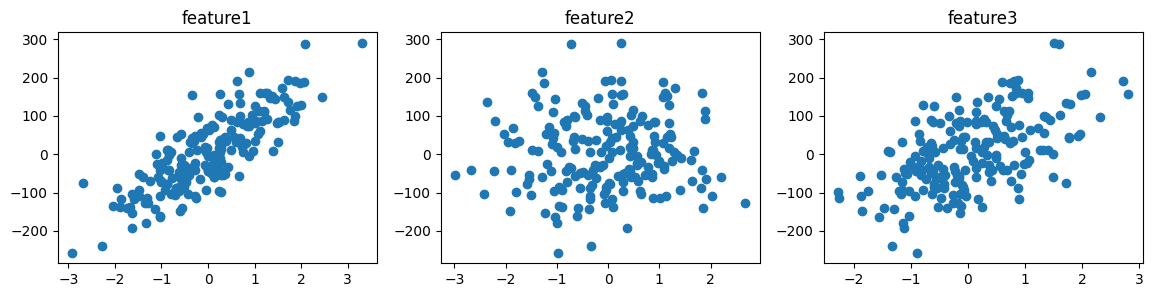

In [48]:
import matplotlib.pyplot as plt
fig,(ax1,ax2,ax3)=plt.subplots(ncols=3,figsize=(14,3))
ax1.scatter(df['feature1'],df['target'])
ax1.set_title("feature1")
ax2.scatter(df['feature2'],df['target'])
ax2.set_title("feature2")
ax3.scatter(df['feature3'],df['target'])
ax3.set_title("feature3")

plt.show()



# multicollinearity

In [49]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif=[]
for i in range(x_train.shape[1]):
    vif.append(variance_inflation_factor(x_train,i))

In [50]:
pd.DataFrame({'vif':vif},index=df.columns[0:3]).T

,feature1,feature2,feature3
vif,1.010326,1.009871,1.01395


<Axes: >

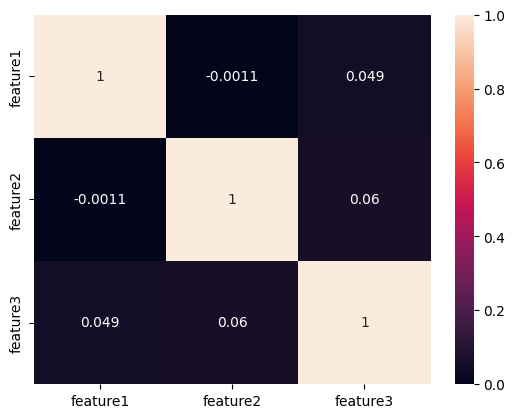

In [51]:
# Another Technique
sns.heatmap(df.iloc[:,0:3].corr(),annot=True)

# normal residual

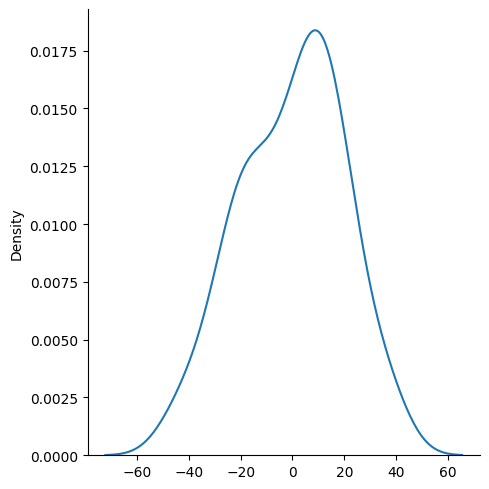

In [ ]:
sns.displot(residual,kind='kde')   # error sh ould be  normally distributed

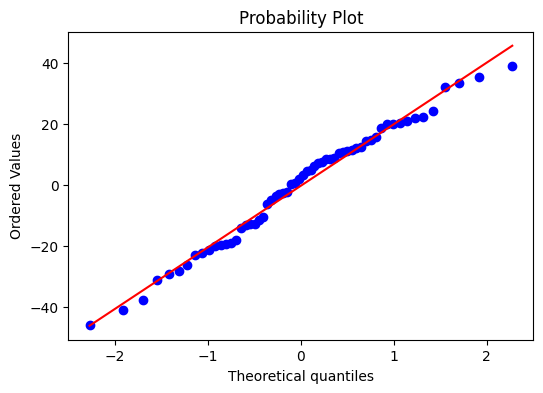

In [ ]:

# QQ Plot   # error normally distributed

import scipy as sp

fig, ax = plt.subplots(figsize=(6,4))
sp.stats.probplot(residual, plot=ax, fit=True)

plt.show()

# Homoscedasticity

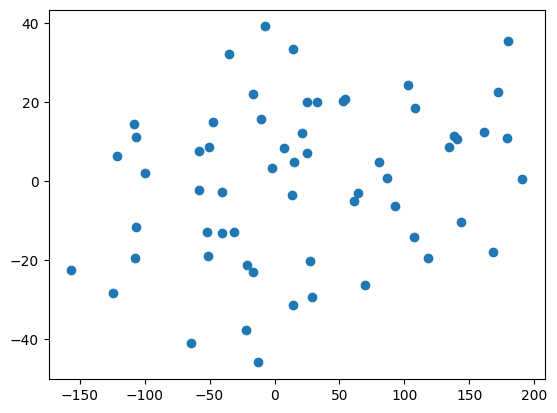

In [54]:
plt.scatter(y_pred,residual)

# No Autocorrelation of Error

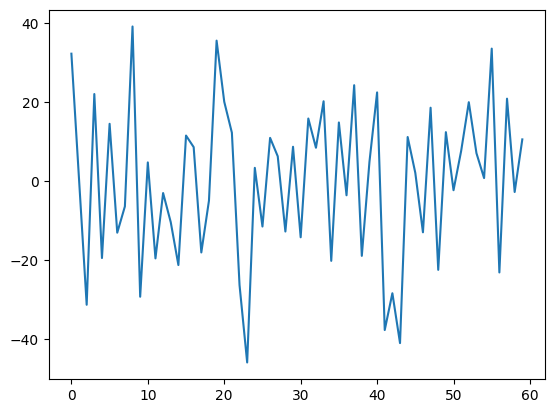

In [ ]:
plt.plot(residual) # good